# Persian License Plate Detection and Recognition

YOLO11 detects plates; a scratch CNN and a pretrained ResNet18 recognize eight plate **tokens**. A middle word such as `الف` is one token, even though it contains several Unicode characters.

# Phase 1: License plate detection with YOLO

## Setup:

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%pip install -q ultralytics matplotlib opencv-python pyyaml gdown pandas scikit-learn tqdm pillow ipython arabic-reshaper python-bidi
# PyTorch and torchvision are already installed in Google Colab.
%pip install -q torch torchvision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 98.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.2 MB/s eta 0:00:00


In [3]:
import os
import shutil
import random
import re
import unicodedata
import zipfile
from pathlib import Path

import gdown
import yaml
from tqdm.auto import tqdm
from IPython.display import display
import arabic_reshaper
from bidi.algorithm import get_display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
from torchvision import models, transforms
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Keep the original Colab paths, with a local fallback outside Colab.
base_dir = Path("/content") if Path("/content").exists() else Path.cwd()
root = base_dir / "LPD_FILES"
root_lpr = base_dir / "LPR_FILES"

Using device: cuda


## Preparing the dataset

In [5]:
lpd_zip = "/content/drive/MyDrive/Bootcamp/Plate/LPD.zip"

In [6]:
root.mkdir(parents=True, exist_ok=True)
if not (root / "images").exists() or not (root / "labels").exists():
    with zipfile.ZipFile(lpd_zip) as archive:
        archive.extractall(root)

In [7]:
# Check the data.
exts = {".jpg", ".jpeg", ".png", ".bmp"}
img_dir, lbl_dir = root / "images", root / "labels"

for f in sorted(lbl_dir.rglob("*.txt"))[:3]:
    print(f.name, "->", f.read_text().strip())

imgs = {p.relative_to(img_dir).with_suffix("") for p in img_dir.rglob("*") if p.suffix.lower() in exts}
lbls = {p.relative_to(lbl_dir).with_suffix("") for p in lbl_dir.rglob("*.txt")}
print(len(imgs), len(lbls), "| no label:", len(imgs - lbls), "| no image:", len(lbls - imgs))

000001.txt -> 0 0.5567708333333333 0.276953125 0.08020833333333334 0.01484375
000002.txt -> 0 0.4630208333333333 0.29609375 0.084375 0.015625
000003.txt -> 0 0.484375 0.375 0.26458333333333334 0.0390625
6252 6252 | no label: 0 | no image: 0


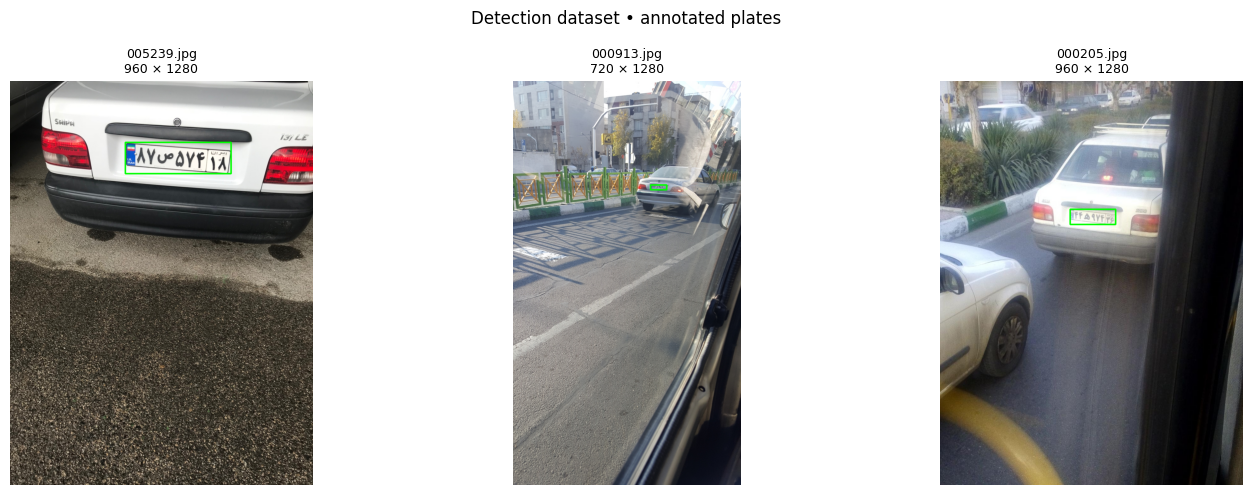

In [8]:
all_img_paths = sorted(p for p in img_dir.rglob("*") if p.suffix.lower() in exts)
samples = random.Random(SEED).sample(all_img_paths, min(3, len(all_img_paths)))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax in axes:
    ax.axis("off")
for ax, img_path in zip(axes, samples):
    img = cv2.imread(str(img_path))
    if img is None:
        raise ValueError(f"Cannot read image: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl_path = (lbl_dir / img_path.relative_to(img_dir)).with_suffix(".txt")
    if lbl_path.exists():
        for line in lbl_path.read_text().strip().splitlines():
            c, x, y, bw, bh = map(float, line.split())
            x1, y1 = int((x - bw / 2) * w), int((y - bh / 2) * h)
            x2, y2 = int((x + bw / 2) * w), int((y + bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
    ax.imshow(img)
    ax.set_title(f"{img_path.name}\n{w} × {h}", fontsize=9)
fig.suptitle("Detection dataset • annotated plates")
plt.tight_layout()
plt.show()

In [9]:
lpd_df = pd.read_csv(root / "plate_labels.csv", dtype=str, keep_default_na=False)
lpd_df.head()

,index,image_path,label
0,1,000001.jpg,48و15116
1,2,000002.jpg,78س92616
2,3,000003.jpg,73ب31536
3,4,000004.jpg,35و33669
4,5,000005.jpg,39ص29449


In [10]:
print("Rows in CSV:", len(lpd_df))
print("Images on disk:", len(all_img_paths))
image_names = {p.name for p in all_img_paths}
missing = [name for name in lpd_df["image_path"] if name not in image_names]
print("CSV entries with no image:", len(missing))

Rows in CSV: 6252
Images on disk: 6252
CSV entries with no image: 0


In [11]:
# Find matched images and labels; keep the source files in place.
pairs = []
for p in sorted(all_img_paths, key=lambda p: p.name):
    label_path = (lbl_dir / p.relative_to(img_dir)).with_suffix(".txt")
    if label_path.exists():
        pairs.append(p)
if not pairs:
    raise ValueError("No matched detection images and labels were found.")
print("Usable image/label pairs:", len(pairs))

Usable image/label pairs: 6252


In [12]:
# YOLO accepts text files containing image paths, so reruns need not move files.
random.Random(SEED).shuffle(pairs)
n = len(pairs)
splits = {
    "train": pairs[:int(0.8 * n)],
    "val": pairs[int(0.8 * n):int(0.9 * n)],
    "test": pairs[int(0.9 * n):],
}
for split, files in splits.items():
    (root / f"{split}.txt").write_text(
        "\n".join(str(p.resolve()) for p in files) + "\n", encoding="utf-8"
    )
    print(split, len(files))

train 5001
val 625
test 626


In [13]:
for split, files in splits.items():
    assert files, f"The {split} split is empty."
    assert all(p.exists() for p in files)
assert set(splits["train"]).isdisjoint(splits["val"])
assert set(splits["train"]).isdisjoint(splits["test"])
assert set(splits["val"]).isdisjoint(splits["test"])
assert sum(len(files) for files in splits.values()) == len(pairs)
print("Detection split paths checked.")

Detection split paths checked.


In [14]:
data_yaml = base_dir / "data.yaml"
config = {
    "path": str(root.resolve()),
    "train": "train.txt",
    "val": "val.txt",
    "test": "test.txt",
    "names": {0: "license_plate"},
}
with open(data_yaml, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

In [15]:
# select a YOLO model
model = YOLO("yolo11n.pt")

In [16]:
results = model.train(
    data=str(data_yaml),
    epochs=30,
    imgsz=640,
    batch=16,
    patience=10,
    seed=SEED,
    project=str(base_dir / "runs"),
    name="lpd_yolo11n",
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=lpd_yolo11n, nbs=64, nms=None, opset=None, optimize=False, optimizer=au

In [17]:
# Use this training run's actual path, including any automatic run suffix.
run_dir = Path(model.trainer.save_dir)
best_path = Path(model.trainer.best)
if not best_path.is_file():
    raise FileNotFoundError(f"No best detection checkpoint found: {best_path}")
shutil.copy2(best_path, base_dir / "lpd_best.pt")
model = YOLO(str(base_dir / "lpd_best.pt"))

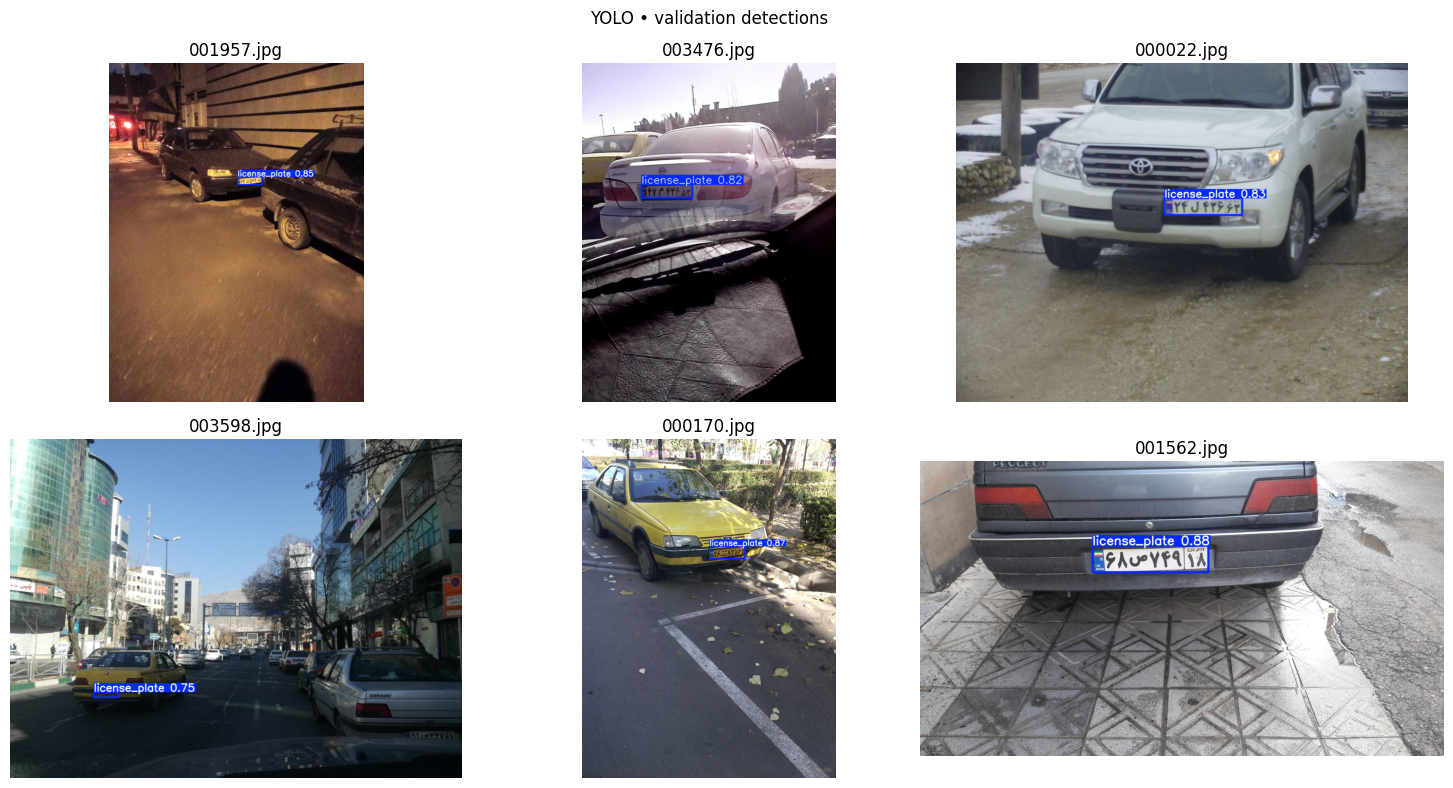

In [18]:
samples = random.Random(SEED).sample(splits["val"], min(6, len(splits["val"])))
results = model.predict([str(p) for p in samples], conf=0.25, verbose=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax in axes.ravel():
    ax.axis("off")
for ax, result in zip(axes.ravel(), results):
    ax.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(Path(result.path).name)
fig.suptitle("YOLO • validation detections")
plt.tight_layout()
plt.show()

In [19]:
print("Training run:", run_dir)
detection_history = pd.read_csv(run_dir / "results.csv")
detection_history.columns = detection_history.columns.str.strip()
detection_history.tail()

Training run: /content/runs/lpd_yolo11n


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,2637.51,0.81024,0.43142,0.88952,0.95525,0.94214,0.97821,0.75687,0.78077,0.42758,0.89118,0.000350,0.000350,0.000350
26,27,2738.32,0.80926,0.42283,0.88748,0.95338,0.94483,0.97726,0.75094,0.77849,0.41927,0.89171,0.000284,0.000284,0.000284
27,28,2836.87,0.79648,0.40842,0.88636,0.96229,0.95041,0.97915,0.76184,0.77192,0.39882,0.89244,0.000218,0.000218,0.000218
28,29,2935.45,0.78463,0.40950,0.88362,0.94705,0.94483,0.97806,0.76478,0.75908,0.40523,0.89000,0.000152,0.000152,0.000152
29,30,3034.33,0.78198,0.40093,0.88003,0.95147,0.94644,0.98075,0.76982,0.75907,0.39452,0.89301,0.000086,0.000086,0.000086


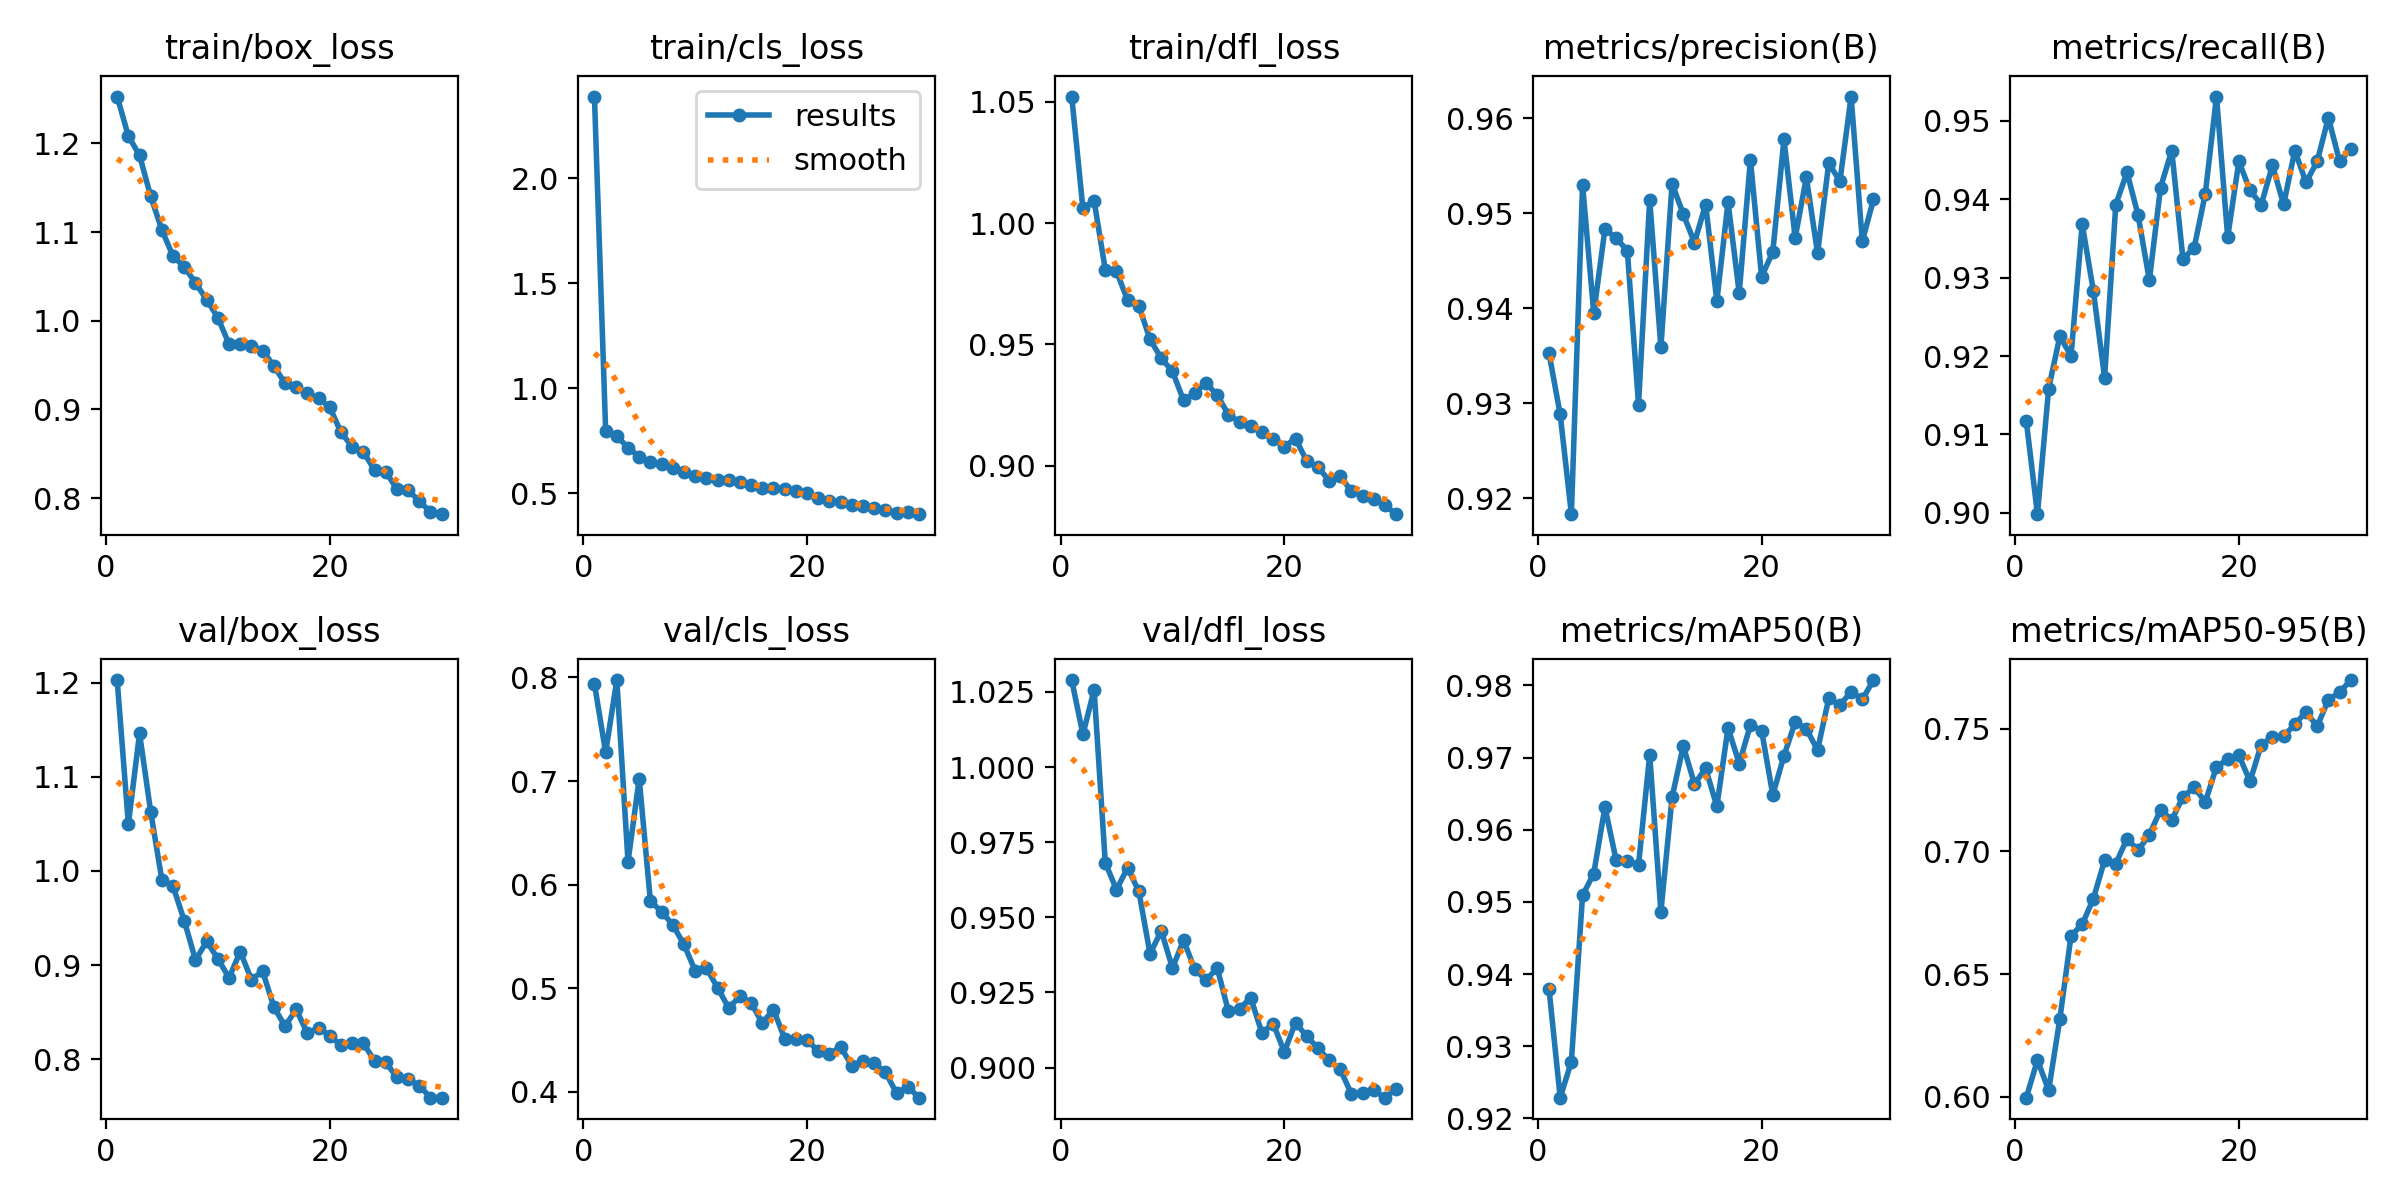

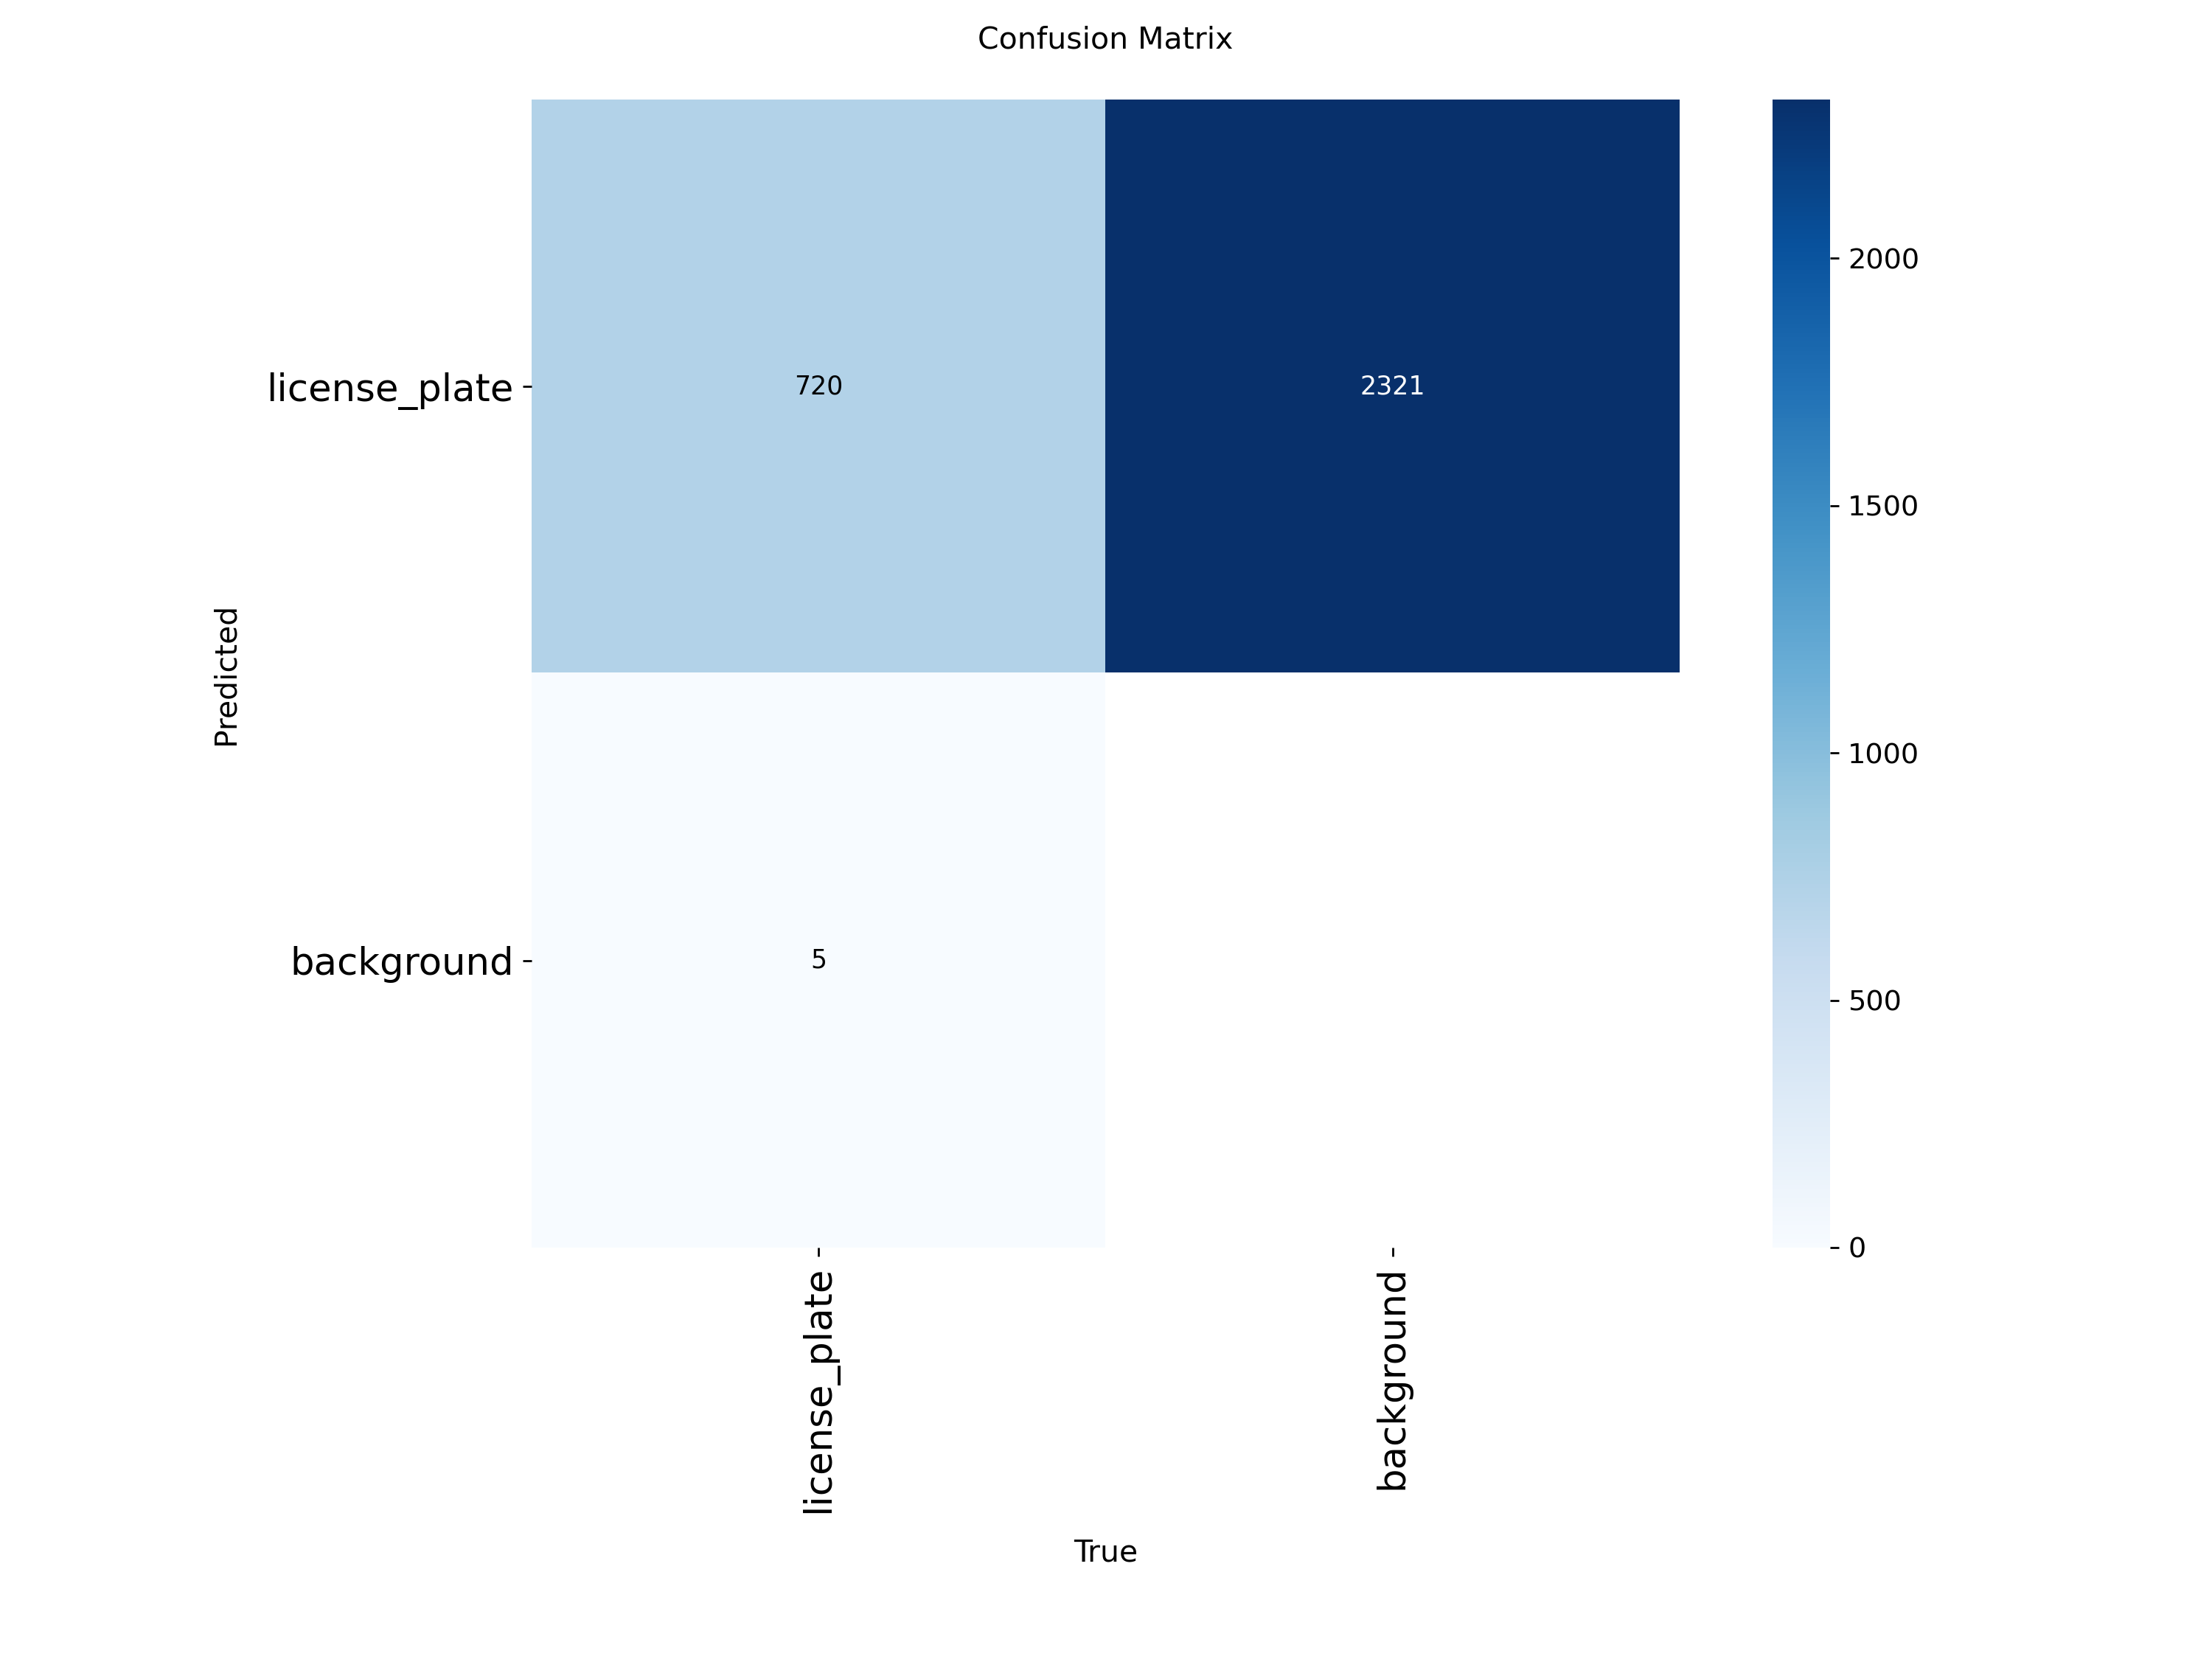

In [20]:
for name in ["results.png", "confusion_matrix.png"]:
    path = run_dir / name
    if path.exists():
        with Image.open(path) as img:
            display(img.copy())

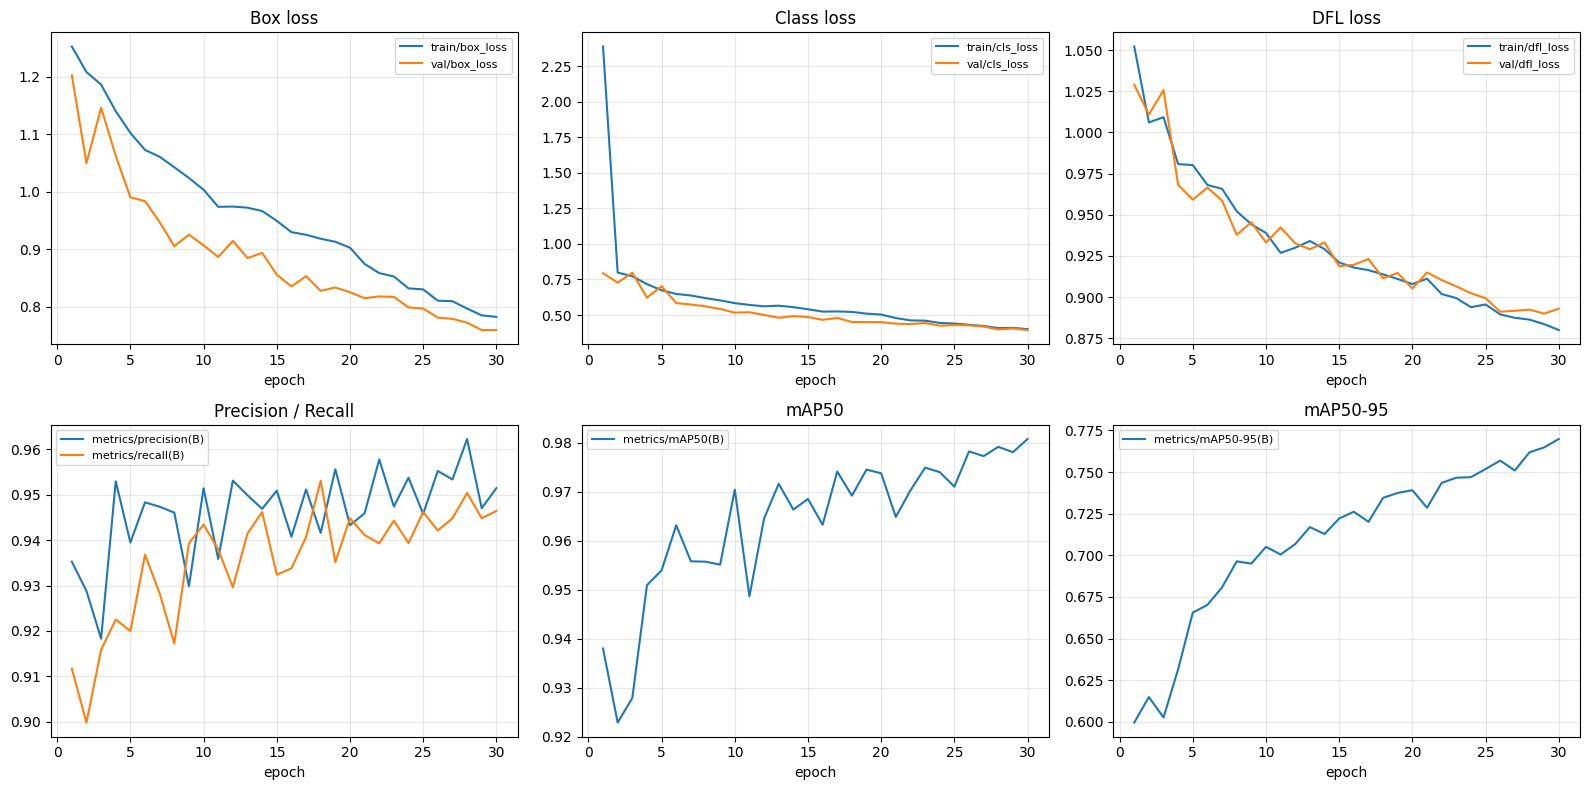

In [21]:
plots = [
    ("Box loss",           ["train/box_loss", "val/box_loss"]),
    ("Class loss",         ["train/cls_loss", "val/cls_loss"]),
    ("DFL loss",           ["train/dfl_loss", "val/dfl_loss"]),
    ("Precision / Recall", ["metrics/precision(B)", "metrics/recall(B)"]),
    ("mAP50",              ["metrics/mAP50(B)"]),
    ("mAP50-95",           ["metrics/mAP50-95(B)"]),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (title, cols) in zip(axes.ravel(), plots):
    for c in cols:
        ax.plot(detection_history["epoch"], detection_history[c], label=c)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
metrics = model.val(data=str(data_yaml), split="test")

print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")
print(f"mAP50     : {metrics.box.map50:.4f}")
print(f"mAP50-95  : {metrics.box.map:.4f}")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 302.3±93.1 MB/s, size: 479.7 KB)
val: Scanning /content/LPD_FILES/labels... 626 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 626/626 506.5it/s 1.2s
val: New cache created: /content/LPD_FILES/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 3.9it/s 10.3s
                   all        626        703      0.937      0.955      0.985      0.761
Speed: 1.7ms preprocess, 4.4ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs/detect/val
Precision : 0.9372
Recall    : 0.9552
mAP50     : 0.9847
mAP50-95  : 0.7615


# Phase 2: License Plate Recognition - CNN

In [23]:
lpr_zip = "/content/drive/MyDrive/Bootcamp/Plate/LPR.zip"

In [24]:
root_lpr.mkdir(parents=True, exist_ok=True)
if not (root_lpr / "detections").exists() or not (root_lpr / "valid_samples.csv").exists():
    with zipfile.ZipFile(lpr_zip) as archive:
        archive.extractall(root_lpr)

In [25]:
df = pd.read_csv(root_lpr / "valid_samples.csv", dtype=str, keep_default_na=False)
print(df.shape)
print(df.head())
missing = [name for name in df["image_path"] if not (root_lpr / "detections" / name).is_file()]
if missing:
    raise FileNotFoundError(f"{len(missing)} recognition images are missing; first: {missing[:5]}")
if df["image_path"].duplicated().any():
    raise ValueError("Repeated image filenames in the recognition CSV need to be checked.")

(24561, 2)
  image_path     label
0      1.jpg  98ع89511
1      2.jpg  19ش24611
2      3.jpg  25ت71433
3      4.jpg  95ت38633
4      5.jpg  44ه67355


(548, 246)


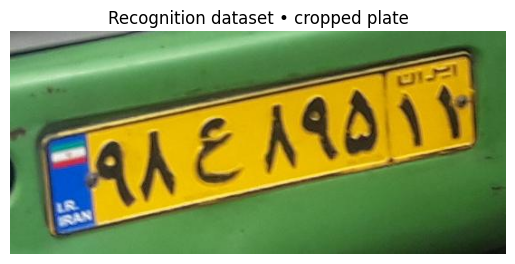

In [26]:
sample_name = df.iloc[0]["image_path"]
with Image.open(root_lpr / "detections" / sample_name) as img:
    print(img.size)
    plt.imshow(img.convert("RGB"))
plt.title("Recognition dataset • cropped plate")
plt.axis("off")
plt.show()

## Normalize and tokenize plate labels

The supported layout is **two digits + one letter/word token + five digits**. Persian and Arabic digits are normalized to ASCII digits; text-formatting joiners are removed. For example, `12الف34567` becomes `["1", "2", "الف", "3", "4", "5", "6", "7"]`. Invalid layouts are reported for correction instead of silently discarded.

In [27]:
def normalize_label(s):
    if not isinstance(s, str):
        raise ValueError("Plate labels must be strings.")
    s = unicodedata.normalize("NFKC", s)
    s = s.translate(str.maketrans({"ي": "ی", "ى": "ی", "ك": "ک"}))
    cleaned = []
    for char in s:
        # Joiners and text-direction controls are formatting, not plate classes.
        if char.isspace() or unicodedata.category(char) == "Cf":
            continue
        if char.isdecimal():
            char = str(unicodedata.decimal(char))
        cleaned.append(char)
    return "".join(cleaned)


def tokenize_label(s):
    s = normalize_label(s)
    match = re.fullmatch(r"([0-9]{2})([^0-9]+)([0-9]{5})", s)
    if match is None:
        raise ValueError(f"Expected two digits, a letter/word, and five digits: {s!r}")
    first, middle, last = match.groups()
    if not all(unicodedata.category(char)[0] in ("L", "M") for char in middle):
        raise ValueError(f"Unexpected middle symbol in label: {s!r}")
    return list(first) + [middle] + list(last)


# Eight positions, even when the middle token contains several letters.
assert tokenize_label("12الف34567") == ["1", "2", "الف", "3", "4", "5", "6", "7"]
assert tokenize_label("12ه\u200d34567") == tokenize_label("12ه34567")
assert tokenize_label("۱۲الف۳۴۵۶۷") == tokenize_label("12الف34567")

In [28]:
# Keep every row; inspect the old character lengths before normalization.
df["raw_label"] = df["label"]
print("Raw Unicode lengths:")
print(df["raw_label"].str.len().value_counts().sort_index())
df["label"] = df["raw_label"].apply(normalize_label)

plate_tokens = []
invalid_labels = []
for row in df.itertuples():
    try:
        plate_tokens.append(tokenize_label(row.label))
    except ValueError as error:
        invalid_labels.append((row.image_path, str(error)))
if invalid_labels:
    raise ValueError(f"Check these labels; no rows were silently discarded: {invalid_labels[:10]}")
df["tokens"] = plate_tokens
df["middle_token"] = df["tokens"].apply(lambda tokens: tokens[2])
print("\nMiddle-token counts:")
print(df["middle_token"].value_counts())

Raw Unicode lengths:
raw_label
8     23519
9       997
10       45
Name: count, dtype: int64

Middle-token counts:
middle_token
د      2267
ص      2255
ق      2018
م      1903
ج      1901
ب      1862
و      1828
س      1749
ط      1724
ل      1518
ن      1480
ه      1421
ی      1332
ت       709
ع       491
الف      45
ژ        30
آ        21
ث         3
ش         2
ز         1
پ         1
Name: count, dtype: int64


In [29]:
# Replaces the old len(label) == 8 filter.
assert len(df) == len(plate_tokens)
assert df["tokens"].apply(len).eq(8).all()
print(f"Kept all {len(df):,} valid plates.")
print(f"Labels previously excluded by the length filter: {df['raw_label'].str.len().ne(8).sum():,}")
print(f"Multi-letter middle tokens: {df['middle_token'].str.len().gt(1).sum():,}")

Kept all 24,561 valid plates.
Labels previously excluded by the length filter: 1,042
Multi-letter middle tokens: 45


## Split and encode

Split distinct normalized plate labels within each middle-token group, then assign all corresponding images together. Groups with fewer than three distinct plates stay in training. The displayed counts show which rare tokens cannot be evaluated separately. The ratio is approximately 70/15/15 by distinct plate labels, not an exact image-count ratio.

In [30]:
# Keep all images of the same normalized plate in one split.
# Split within middle-token groups so every class has training examples.
def split_recognition_data(df, seed=42):
    rng = random.Random(seed)
    train_labels, val_labels, test_labels = [], [], []
    for middle, group in df.groupby("middle_token", sort=True):
        labels = sorted(group["label"].unique())
        rng.shuffle(labels)
        n = len(labels)
        if n < 3:
            # Too few distinct plates for all three splits: keep them in training.
            train_labels.extend(labels)
            continue
        n_val = max(1, int(round(0.15 * n)))
        n_test = max(1, int(round(0.15 * n)))
        n_train = n - n_val - n_test
        train_labels.extend(labels[:n_train])
        val_labels.extend(labels[n_train:n_train + n_val])
        test_labels.extend(labels[n_train + n_val:])
    train_df = df[df["label"].isin(train_labels)].reset_index(drop=True)
    val_df = df[df["label"].isin(val_labels)].reset_index(drop=True)
    test_df = df[df["label"].isin(test_labels)].reset_index(drop=True)
    if min(len(train_df), len(val_df), len(test_df)) == 0:
        raise ValueError("Not enough distinct plates for nonempty train/validation/test splits.")
    assert len(train_df) + len(val_df) + len(test_df) == len(df)
    assert set(train_df["label"]).isdisjoint(val_df["label"])
    assert set(train_df["label"]).isdisjoint(test_df["label"])
    assert set(val_df["label"]).isdisjoint(test_df["label"])
    return train_df, val_df, test_df


train_df, val_df, test_df = split_recognition_data(df, seed=SEED)
print("Train / validation / test:", len(train_df), len(val_df), len(test_df))
coverage = pd.DataFrame({
    "train": train_df["middle_token"].value_counts(),
    "val": val_df["middle_token"].value_counts(),
    "test": test_df["middle_token"].value_counts(),
}).fillna(0).astype(int)
display(coverage)
assert set(df["middle_token"]) <= set(train_df["middle_token"])

Train / validation / test: 17295 3662 3604


,train,val,test
middle_token,,,
آ,15,3,3
الف,31,7,7
ب,1316,276,270
ت,495,106,108
ث,1,1,1
ج,1334,289,278
د,1601,333,333
ز,1,0,0
س,1226,263,260


In [31]:
# Digits are known plate symbols; middle tokens come from the training split.
tokens = list("0123456789") + sorted(train_df["middle_token"].unique())
token_to_idx = {token: i for i, token in enumerate(tokens)}
idx_to_token = {i: token for token, i in token_to_idx.items()}
num_classes = len(tokens)
num_positions = 8
print(num_classes, tokens)

32 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'آ', 'الف', 'ب', 'ت', 'ث', 'ج', 'د', 'ز', 'س', 'ش', 'ص', 'ط', 'ع', 'ق', 'ل', 'م', 'ن', 'ه', 'و', 'پ', 'ژ', 'ی']


In [32]:
def encode_label(s):
    return [token_to_idx[token] for token in tokenize_label(s)]


def decode_label(indices):
    return "".join(idx_to_token[int(i)] for i in indices)


def display_label(s):
    # Reshape only for plotting; keep logical text order for training and comparison.
    return get_display(arabic_reshaper.reshape(s))


for label in df["label"]:
    assert decode_label(encode_label(label)) == label
print("Every label encodes and decodes correctly.")

Every label encodes and decodes correctly.


In [33]:
sample_sizes = []
for name in df["image_path"].sample(min(50, len(df)), random_state=0):
    with Image.open(root_lpr / "detections" / name) as img:
        sample_sizes.append(img.size)
ws, hs = zip(*sample_sizes)
print("Width range:", min(ws), max(ws), "height range:", min(hs), max(hs))

Width range: 56 2511 height range: 16 503


In [34]:
IMG_SIZE = (128, 64)  # width, height
train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE[::-1]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5] * 3, std=[0.5] * 3),
])
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
resnet_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE[::-1]),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

In [35]:
class PLPRDataset(data.Dataset):
    def __init__(self, df, img_dir, transform):
        self.df = df.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(self.img_dir / row["image_path"]) as img:
            img = img.convert("RGB")
        img = self.transform(img)
        label = torch.tensor(encode_label(row["label"]), dtype=torch.long)
        return img, label

In [36]:
BATCH_SIZE = 64
NUM_WORKERS = 0  # Works in Colab and local notebooks.

train_ds = PLPRDataset(train_df, root_lpr / "detections", train_transform)
val_ds = PLPRDataset(val_df, root_lpr / "detections", train_transform)
test_ds = PLPRDataset(test_df, root_lpr / "detections", train_transform)
train_loader = data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = data.DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = data.DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

train_ds_resnet = PLPRDataset(train_df, root_lpr / "detections", resnet_transform)
val_ds_resnet = PLPRDataset(val_df, root_lpr / "detections", resnet_transform)
test_ds_resnet = PLPRDataset(test_df, root_lpr / "detections", resnet_transform)
train_loader_resnet = data.DataLoader(train_ds_resnet, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader_resnet = data.DataLoader(val_ds_resnet, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader_resnet = data.DataLoader(test_ds_resnet, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)  # [batch, 3, 64, 128], [batch, 8 tokens]

torch.Size([64, 3, 64, 128]) torch.Size([64, 8])


## Models, loss, and metrics

Both recognizers retain eight output heads. The third head can predict a complete word token. **Token accuracy** counts correct plate positions; **plate accuracy** requires all eight positions to match. These are not Unicode-character accuracy scores. Epoch metrics weight every sample equally, including the final smaller batch.

In [37]:
class PLPRResNet(nn.Module):
    def __init__(self, num_classes, num_positions=8, freeze_backbone=False,
                 weights=models.ResNet18_Weights.IMAGENET1K_V1):
        super().__init__()
        backbone = models.resnet18(weights=weights)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False
        self.heads = nn.ModuleList([
            nn.Linear(feat_dim, num_classes) for _ in range(num_positions)
        ])

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            self.backbone.eval()  # Also freeze BatchNorm running statistics.
        return self

    def forward(self, x):
        feats = self.backbone(x)
        logits = torch.stack([head(feats) for head in self.heads], dim=1)
        return logits

In [38]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class PLPRScratchCNN(nn.Module):
    def __init__(self, num_classes, num_positions=8, dropout=0.3):
        super().__init__()

        def block(in_ch, out_ch, pool=True):
            layers = [
                nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            ]
            if pool:
                layers.append(nn.MaxPool2d(2))
            return nn.Sequential(*layers)

        self.stem = block(3, 32)
        self.res1 = ResidualBlock(32)
        self.stage2 = block(32, 64)
        self.res2 = ResidualBlock(64)
        self.stage3 = block(64, 128)
        self.stage4 = block(128, 256)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)

        self.heads = nn.ModuleList([
            nn.Linear(256, num_classes) for _ in range(num_positions)
        ])

    def forward(self, x):
        x = self.stem(x)
        x = self.res1(x)
        x = self.stage2(x)
        x = self.res2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)
        logits = torch.stack([head(x) for head in self.heads], dim=1)
        return logits

In [39]:
def multihead_loss(logits, targets):
    # Each head learns one plate token, including a whole word such as الف.
    if logits.shape[:2] != targets.shape:
        raise ValueError("Expected logits [batch, 8, classes] and targets [batch, 8].")
    losses = [
        nn.functional.cross_entropy(logits[:, i, :], targets[:, i])
        for i in range(logits.shape[1])
    ]
    return torch.stack(losses).mean()


def accuracy(logits, targets):
    preds = logits.argmax(dim=2)
    per_token = (preds == targets).float().mean().item()
    per_plate = (preds == targets).all(dim=1).float().mean().item()
    return per_token, per_plate


def run_epoch(model, loader, optimizer=None, train=True):
    if train and optimizer is None:
        raise ValueError("Training requires an optimizer.")
    model.train(train)
    total_loss, correct_tokens, correct_plates = 0.0, 0, 0
    n_samples, n_tokens = 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if train:
                optimizer.zero_grad()
            logits = model(xb)
            loss = multihead_loss(logits, yb)
            if train:
                loss.backward()
                optimizer.step()
            preds = logits.argmax(dim=2)
            total_loss += loss.item() * len(xb)
            correct_tokens += (preds == yb).sum().item()
            correct_plates += (preds == yb).all(dim=1).sum().item()
            n_samples += len(xb)
            n_tokens += yb.numel()
    if n_samples == 0:
        raise ValueError("The data loader is empty.")
    return total_loss / n_samples, correct_tokens / n_tokens, correct_plates / n_samples

In [40]:
checkpoint_dir = root_lpr / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)


def save_recognition_checkpoint(model, path, model_name, epoch, val_loss, val_plate_acc):
    torch.save({
        "model_state": model.state_dict(),
        "model_name": model_name,
        "tokens": tokens,
        "num_positions": num_positions,
        "image_size": IMG_SIZE,
        "normalization": "imagenet" if model_name == "resnet18" else "half",
        "epoch": epoch,
        "val_loss": val_loss,
        "val_plate_acc": val_plate_acc,
    }, path)

## Train ResNet18

Fine-tune the pretrained backbone and eight heads. Save the checkpoint with the lowest validation loss, including its vocabulary and preprocessing settings.

In [41]:
model_resnet = PLPRResNet(num_classes=num_classes, num_positions=num_positions).to(device)
optimizer_resnet = optim.Adam(model_resnet.parameters(), lr=1e-4)
scheduler_resnet = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_resnet, mode="min", factor=0.5, patience=2
)
EPOCHS = 15
history_resnet = {"train_loss": [], "val_loss": [], "train_token_acc": [],
                       "val_token_acc": [], "val_plate_acc": []}
best_val_loss_resnet = float("inf")
checkpoint_resnet = checkpoint_dir / "resnet_best.pt"

for epoch in range(EPOCHS):
    tr_loss, tr_token_acc, _ = run_epoch(model_resnet, train_loader_resnet, optimizer_resnet, train=True)
    val_loss, val_token_acc, val_plate_acc = run_epoch(model_resnet, val_loader_resnet, train=False)
    scheduler_resnet.step(val_loss)
    history_resnet["train_loss"].append(tr_loss)
    history_resnet["val_loss"].append(val_loss)
    history_resnet["train_token_acc"].append(tr_token_acc)
    history_resnet["val_token_acc"].append(val_token_acc)
    history_resnet["val_plate_acc"].append(val_plate_acc)
    if val_loss < best_val_loss_resnet:
        best_val_loss_resnet = val_loss
        save_recognition_checkpoint(model_resnet, checkpoint_resnet,
                                    "resnet18", epoch + 1, val_loss, val_plate_acc)
    print(f"epoch {epoch + 1}/{EPOCHS} | train_loss {tr_loss:.4f} | val_loss {val_loss:.4f} "
          f"| val_token_acc {val_token_acc:.4f} | val_plate_acc {val_plate_acc:.4f}")

best_resnet = torch.load(checkpoint_resnet, map_location=device, weights_only=True)
assert best_resnet["tokens"] == tokens
model_resnet.load_state_dict(best_resnet["model_state"])
print("Loaded best validation-loss checkpoint from epoch", best_resnet["epoch"])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


epoch 1/15 | train_loss 1.8764 | val_loss 1.0399 | val_token_acc 0.6855 | val_plate_acc 0.0522
epoch 2/15 | train_loss 0.6606 | val_loss 0.4356 | val_token_acc 0.9007 | val_plate_acc 0.5363
epoch 3/15 | train_loss 0.2938 | val_loss 0.2561 | val_token_acc 0.9441 | val_plate_acc 0.7343
epoch 4/15 | train_loss 0.1620 | val_loss 0.2003 | val_token_acc 0.9548 | val_plate_acc 0.7848
epoch 5/15 | train_loss 0.0996 | val_loss 0.1694 | val_token_acc 0.9602 | val_plate_acc 0.8119
epoch 6/15 | train_loss 0.0634 | val_loss 0.1558 | val_token_acc 0.9622 | val_plate_acc 0.8217
epoch 7/15 | train_loss 0.0423 | val_loss 0.1453 | val_token_acc 0.9637 | val_plate_acc 0.8307
epoch 8/15 | train_loss 0.0281 | val_loss 0.1398 | val_token_acc 0.9653 | val_plate_acc 0.8370
epoch 9/15 | train_loss 0.0200 | val_loss 0.1375 | val_token_acc 0.9655 | val_plate_acc 0.8381
epoch 10/15 | train_loss 0.0147 | val_loss 0.1297 | val_token_acc 0.9669 | val_plate_acc 0.8441
epoch 11/15 | train_loss 0.0113 | val_loss 0.1303

## Train the scratch CNN

In [42]:
model_scratch = PLPRScratchCNN(num_classes=num_classes, num_positions=num_positions).to(device)
optimizer_scratch = optim.Adam(model_scratch.parameters(), lr=1e-3)
scheduler_scratch = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_scratch, mode="min", factor=0.5, patience=2
)
EPOCHS = 20
history_scratch = {"train_loss": [], "val_loss": [], "train_token_acc": [],
                       "val_token_acc": [], "val_plate_acc": []}
best_val_loss_scratch = float("inf")
checkpoint_scratch = checkpoint_dir / "scratch_best.pt"

for epoch in range(EPOCHS):
    tr_loss, tr_token_acc, _ = run_epoch(model_scratch, train_loader, optimizer_scratch, train=True)
    val_loss, val_token_acc, val_plate_acc = run_epoch(model_scratch, val_loader, train=False)
    scheduler_scratch.step(val_loss)
    history_scratch["train_loss"].append(tr_loss)
    history_scratch["val_loss"].append(val_loss)
    history_scratch["train_token_acc"].append(tr_token_acc)
    history_scratch["val_token_acc"].append(val_token_acc)
    history_scratch["val_plate_acc"].append(val_plate_acc)
    if val_loss < best_val_loss_scratch:
        best_val_loss_scratch = val_loss
        save_recognition_checkpoint(model_scratch, checkpoint_scratch,
                                    "scratch_cnn", epoch + 1, val_loss, val_plate_acc)
    print(f"epoch {epoch + 1}/{EPOCHS} | train_loss {tr_loss:.4f} | val_loss {val_loss:.4f} "
          f"| val_token_acc {val_token_acc:.4f} | val_plate_acc {val_plate_acc:.4f}")

best_scratch = torch.load(checkpoint_scratch, map_location=device, weights_only=True)
assert best_scratch["tokens"] == tokens
model_scratch.load_state_dict(best_scratch["model_state"])
print("Loaded best validation-loss checkpoint from epoch", best_scratch["epoch"])

epoch 1/20 | train_loss 2.2459 | val_loss 2.1079 | val_token_acc 0.2202 | val_plate_acc 0.0000
epoch 2/20 | train_loss 1.7206 | val_loss 1.4748 | val_token_acc 0.4661 | val_plate_acc 0.0014
epoch 3/20 | train_loss 1.0242 | val_loss 0.7525 | val_token_acc 0.7870 | val_plate_acc 0.1835
epoch 4/20 | train_loss 0.5859 | val_loss 0.3648 | val_token_acc 0.9107 | val_plate_acc 0.5541
epoch 5/20 | train_loss 0.3774 | val_loss 0.2381 | val_token_acc 0.9424 | val_plate_acc 0.7165
epoch 6/20 | train_loss 0.2733 | val_loss 0.1615 | val_token_acc 0.9610 | val_plate_acc 0.8129
epoch 7/20 | train_loss 0.2183 | val_loss 0.1522 | val_token_acc 0.9676 | val_plate_acc 0.8564
epoch 8/20 | train_loss 0.1820 | val_loss 0.1239 | val_token_acc 0.9699 | val_plate_acc 0.8596
epoch 9/20 | train_loss 0.1583 | val_loss 0.1092 | val_token_acc 0.9728 | val_plate_acc 0.8755
epoch 10/20 | train_loss 0.1382 | val_loss 0.1000 | val_token_acc 0.9757 | val_plate_acc 0.8891
epoch 11/20 | train_loss 0.1289 | val_loss 0.0864

## Evaluate the best validation checkpoints

=== Scratch CNN ===
Test plate accuracy: 0.9109
Test token accuracy: 0.9818


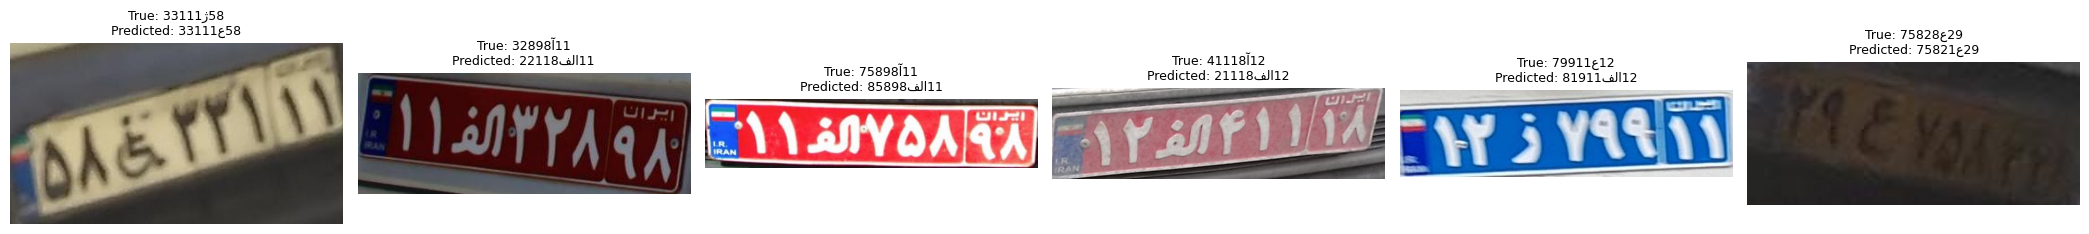

=== ResNet ===
Test plate accuracy: 0.8488
Test token accuracy: 0.9685


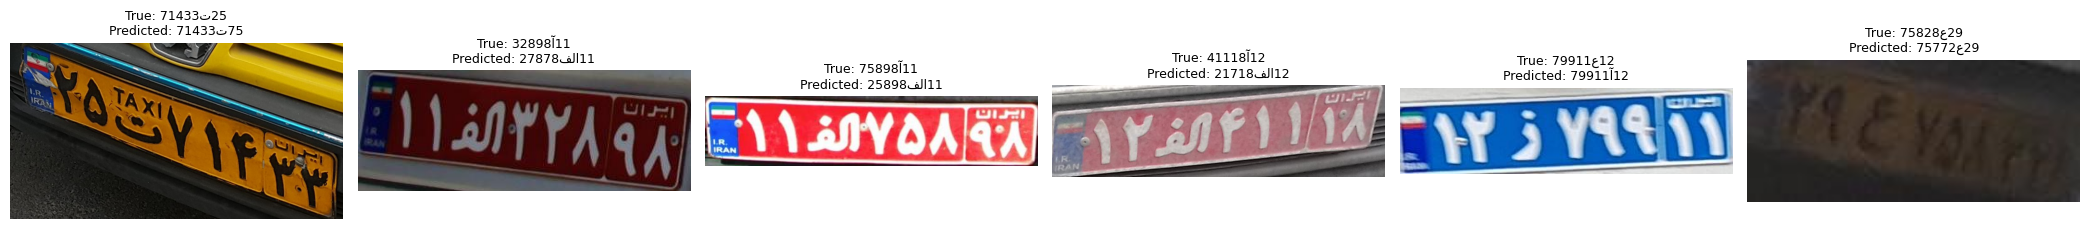

In [43]:
def evaluate_and_show_errors(model, loader, ds, n_show=6):
    if loader.dataset is not ds or not isinstance(loader.sampler, data.SequentialSampler):
        raise ValueError("Use this dataset's non-shuffled evaluation loader to align images and predictions.")
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(device))
            all_preds.append(logits.argmax(dim=2).cpu())
            all_targets.append(yb.cpu())
    if not all_preds:
        raise ValueError("The evaluation loader is empty.")
    all_preds, all_targets = torch.cat(all_preds), torch.cat(all_targets)
    plate_correct = (all_preds == all_targets).all(dim=1)
    print(f"Test plate accuracy: {plate_correct.float().mean().item():.4f}")
    print(f"Test token accuracy: {(all_preds == all_targets).float().mean().item():.4f}")
    wrong_idx = (~plate_correct).nonzero(as_tuple=True)[0][:max(0, n_show)]
    if len(wrong_idx) == 0:
        print("No incorrect examples to display.")
        return all_preds, all_targets
    fig, axes = plt.subplots(1, len(wrong_idx), figsize=(3.5 * len(wrong_idx), 3), squeeze=False)
    for ax, idx in zip(axes.ravel(), wrong_idx):
        row = ds.df.iloc[idx.item()]
        with Image.open(ds.img_dir / row["image_path"]) as img:
            ax.imshow(img.convert("RGB"))
        true_str = display_label(decode_label(all_targets[idx]))
        pred_str = display_label(decode_label(all_preds[idx]))
        ax.set_title(f"True: {true_str}\nPredicted: {pred_str}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return all_preds, all_targets


print("=== Scratch CNN ===")
preds_scratch, targets_scratch = evaluate_and_show_errors(model_scratch, test_loader, test_ds)
print("=== ResNet ===")
preds_resnet, targets_resnet = evaluate_and_show_errors(model_resnet, test_loader_resnet, test_ds_resnet)

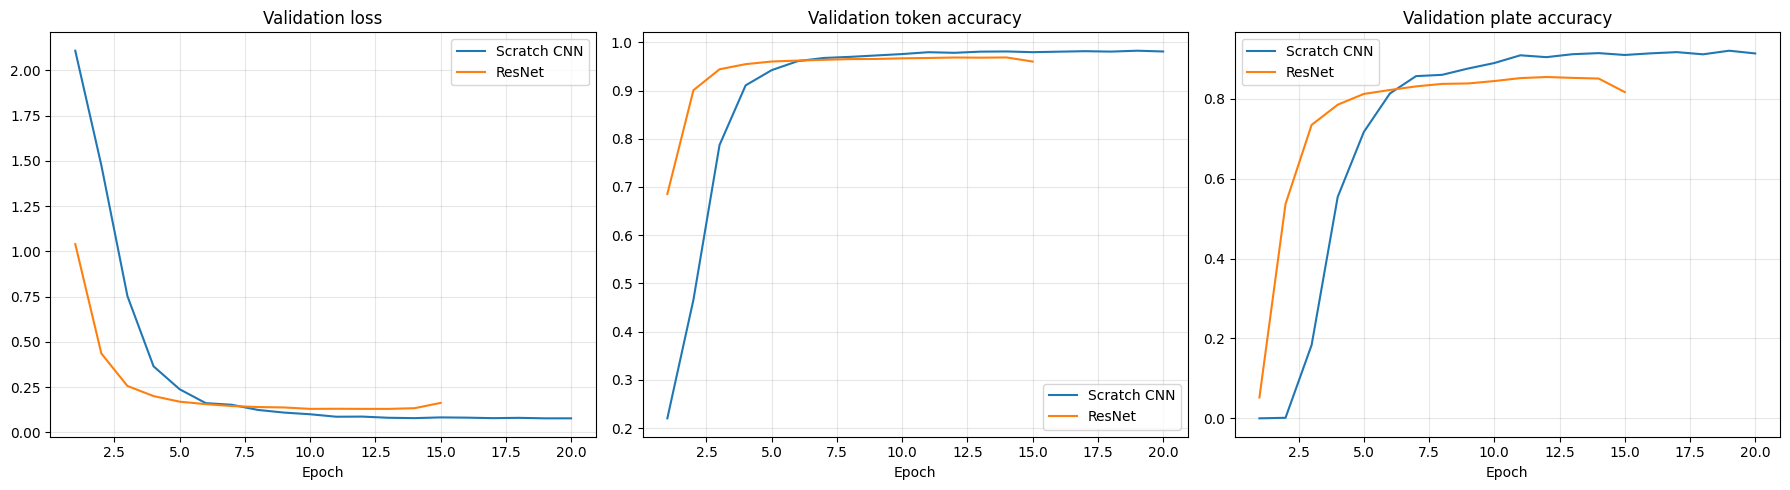

Test plate accuracy — Scratch CNN: 0.9109323024749756
Test plate accuracy — ResNet: 0.8487791419029236


In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plots = [("val_loss", "Validation loss"),
         ("val_token_acc", "Validation token accuracy"),
         ("val_plate_acc", "Validation plate accuracy")]
for ax, (key, title) in zip(axes, plots):
    ax.plot(range(1, len(history_scratch[key]) + 1), history_scratch[key], label="Scratch CNN")
    ax.plot(range(1, len(history_resnet[key]) + 1), history_resnet[key], label="ResNet")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
print("Test plate accuracy — Scratch CNN:", (preds_scratch == targets_scratch).all(dim=1).float().mean().item())
print("Test plate accuracy — ResNet:", (preds_resnet == targets_resnet).all(dim=1).float().mean().item())

# Phase 3: Detection and recognition together

Choose between recognizers using validation accuracy at their saved checkpoints. The pipeline returns the highest-confidence detected plate per image. Ground truth and predictions use the same normalized text convention.

The two datasets may share plate identities or source images. The pipeline report therefore shows label overlap and a separate unseen-label subset where available. Label checks alone do not prove source-image independence.

In [45]:
lpd_model = YOLO(str(base_dir / "lpd_best.pt"))

# Select the recognizer by validation accuracy, not test accuracy.
if best_scratch["val_plate_acc"] >= best_resnet["val_plate_acc"]:
    lpr_model = model_scratch
    lpr_transform = train_transform
    selected_recognizer = "Scratch CNN"
else:
    lpr_model = model_resnet
    lpr_transform = resnet_transform
    selected_recognizer = "ResNet18"
lpr_model.eval()
print("Selected recognizer:", selected_recognizer)

Selected recognizer: Scratch CNN


In [46]:
class LicensePlateRecognizer:
    def __init__(self, lpd_model, lpr_model, transform, idx_to_token, device, conf=0.25):
        self.lpd_model = lpd_model
        self.lpr_model = lpr_model.to(device).eval()
        self.transform = transform
        self.idx_to_token = idx_to_token
        self.device = device
        self.conf = conf

    def predict(self, image_path):
        """Return text, clipped box, and crop for the highest-confidence plate."""
        result = self.lpd_model.predict(str(image_path), conf=self.conf, verbose=False)[0]
        if result.boxes is None or len(result.boxes) == 0:
            return None, None, None
        best_idx = result.boxes.conf.argmax().item()
        box = result.boxes.xyxy[best_idx].cpu().numpy()
        if not np.isfinite(box).all():
            return None, None, None
        with Image.open(image_path) as source:
            img = source.convert("RGB")
        w, h = img.size
        x1 = max(0, min(w, int(np.floor(box[0]))))
        y1 = max(0, min(h, int(np.floor(box[1]))))
        x2 = max(0, min(w, int(np.ceil(box[2]))))
        y2 = max(0, min(h, int(np.ceil(box[3]))))
        if x2 <= x1 or y2 <= y1:
            return None, None, None
        crop = img.crop((x1, y1, x2, y2))
        x = self.transform(crop).unsqueeze(0).to(self.device)
        self.lpr_model.eval()
        with torch.no_grad():
            preds = self.lpr_model(x).argmax(dim=2).squeeze(0).cpu()
        plate_str = "".join(self.idx_to_token[int(i)] for i in preds)
        return plate_str, (x1, y1, x2, y2), crop


pipeline = LicensePlateRecognizer(lpd_model, lpr_model, lpr_transform, idx_to_token, device)

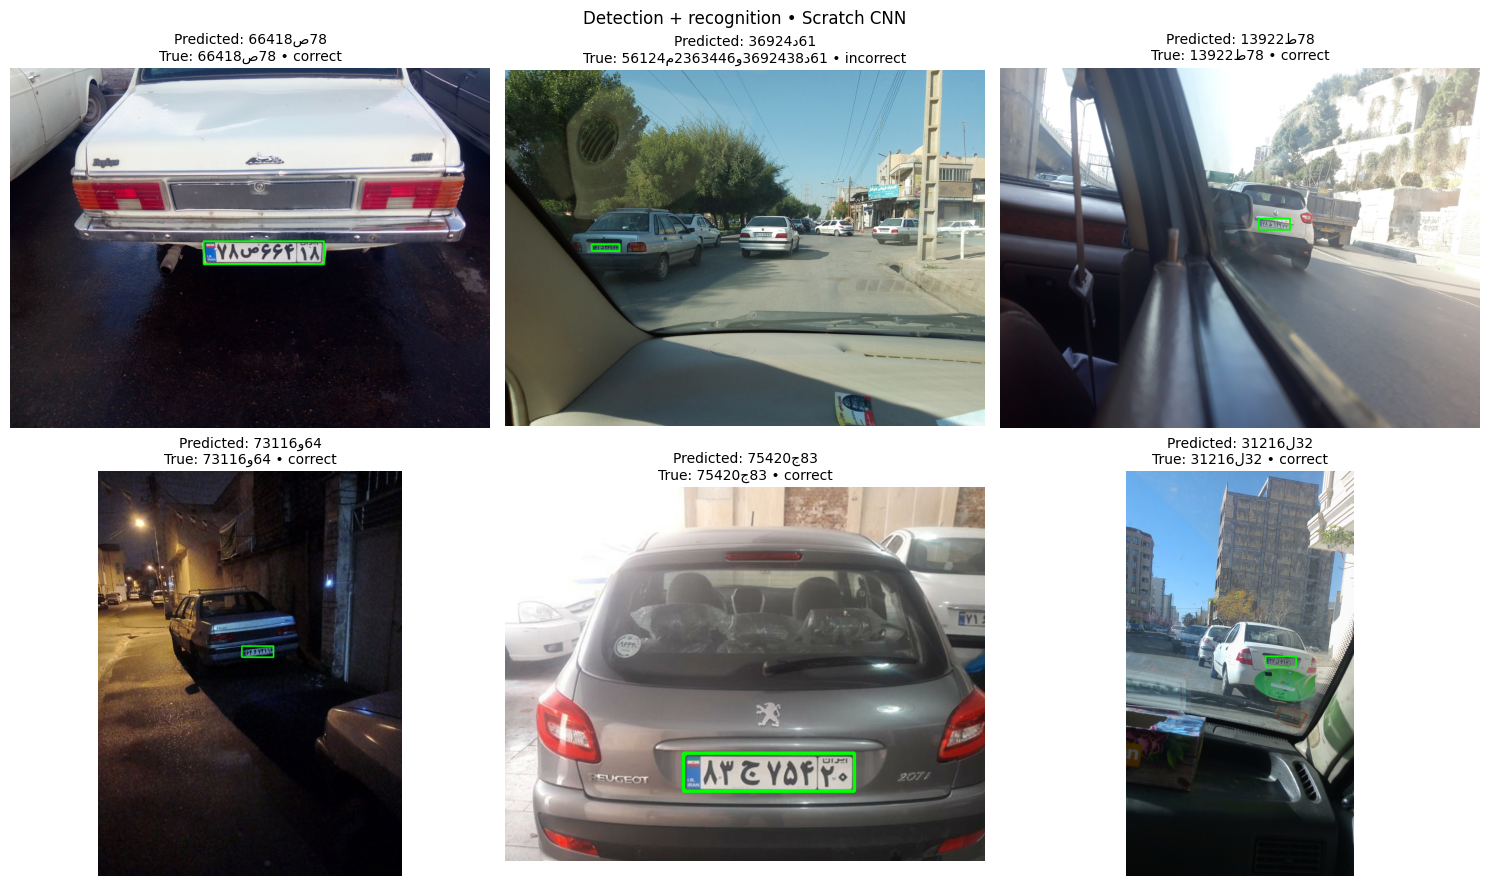

In [47]:
lpd_test_paths = splits["test"]
lpd_df = pd.read_csv(root / "plate_labels.csv", dtype=str, keep_default_na=False)
if lpd_df["image_path"].duplicated().any():
    raise ValueError("Detection CSV has duplicate image names; check the ground-truth mapping.")
gt_lookup = dict(zip(lpd_df["image_path"], lpd_df["label"].apply(normalize_label)))
missing_gt = [p.name for p in lpd_test_paths if p.name not in gt_lookup or not gt_lookup[p.name]]
if missing_gt:
    raise ValueError(f"Missing test ground truth: {missing_gt[:5]}")
samples = random.Random(SEED).sample(lpd_test_paths, min(6, len(lpd_test_paths)))
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax in axes.ravel():
    ax.axis("off")
for ax, img_path in zip(axes.ravel(), samples):
    pred_str, box, crop = pipeline.predict(img_path)
    gt_str = gt_lookup[img_path.name]
    img = cv2.imread(str(img_path))
    if img is None:
        raise ValueError(f"Cannot read image: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if box is not None:
        x1, y1, x2, y2 = box
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
    ax.imshow(img)
    status = "correct" if pred_str == gt_str else "incorrect"
    pred_title = display_label(pred_str) if pred_str is not None else "No plate detected"
    ax.set_title(f"Predicted: {pred_title}\nTrue: {display_label(gt_str)} • {status}", fontsize=10)
fig.suptitle(f"Detection + recognition • {selected_recognizer}")
plt.tight_layout()
plt.show()

In [48]:
# Cache each prediction and report overlap with labels used for training/selection.
seen_labels = set(train_df["label"]) | set(val_df["label"])
for split in ("train", "val"):
    for path in splits[split]:
        label = gt_lookup.get(path.name)
        if label:
            seen_labels.add(label)

pipeline_results = []
for img_path in tqdm(lpd_test_paths):
    pred_str, box, crop = pipeline.predict(img_path)
    gt_str = gt_lookup[img_path.name]
    pipeline_results.append({
        "image": img_path.name,
        "true": gt_str,
        "predicted": pred_str,
        "detected": box is not None,
        "correct": pred_str == gt_str,
        "seen_label": gt_str in seen_labels,
    })
pipeline_results = pd.DataFrame(pipeline_results)
if pipeline_results.empty:
    raise ValueError("No detection test images were evaluated.")
print(f"Pipeline accuracy on LPD test images: {pipeline_results['correct'].mean():.4f}")
print(f"No plate detected: {(~pipeline_results['detected']).sum()}/{len(pipeline_results)}")
print(f"Labels also used in training/validation: {pipeline_results['seen_label'].sum()}")
unseen_results = pipeline_results[~pipeline_results["seen_label"]]
if len(unseen_results):
    print(f"Accuracy on {len(unseen_results)} unseen-label images: {unseen_results['correct'].mean():.4f}")
else:
    print("No unseen-label images are available for a separate pipeline score.")

  0%|          | 0/626 [00:00<?, ?it/s]

Pipeline accuracy on LPD test images: 0.8562
No plate detected: 1/626
Labels also used in training/validation: 445
Accuracy on 181 unseen-label images: 0.6519
